# DS201 · Lab 2: Mạng nơ-ron tích chập (CNN) trên VinaFood21

Notebook thực hành huấn luyện và đánh giá 4 mô hình: LeNet-5, GoogLeNet, ResNet-18 và Pretrained ResNet-50.

> **Lưu ý:** Chọn **Runtime** -> **Change runtime type** -> chọn **T4 GPU** trước khi chạy.

In [1]:
# 0. Clone repo tu GitHub neu dang chay tren Colab
import os, sys

if 'google.colab' in sys.modules:
    if not os.path.exists('data.py'):
        !git clone https://github.com/Alice0602/DS201_Lab2.git /content/DS201_Lab2
        %cd /content/DS201_Lab2
    !git config --global user.name "Alice0602"
    !git config --global user.email "nguyen.phuongtuyen.1002@gmail.com"
    print('Working dir:', os.getcwd())


Cloning into '/content/DS201_Lab2'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (23/23), done.
remote: Total 30 (delta 9), reused 27 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 360.04 KiB | 12.86 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/content/DS201_Lab2
Working dir: /content/DS201_Lab2


In [2]:
# 1. Kiem tra GPU
!nvidia-smi

Wed Oct 28 14:30:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# 2. Cai cac thu vien can thiet
!pip install -q -r requirements.txt

In [4]:
# 3. Tai bo du lieu VinaFood21 tu Google Drive
from data import download_vinafood21
download_vinafood21("VinaFood21")

Downloading...
From (original): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR
From (redirected): https://drive.google.com/uc?id=1UpZOf0XlwvB4rKpyZ35iwTA8oWHqDBbR&confirm=t&uuid=9a7b9bbc-ecd6-49cd-9410-68a6cd7d4892
To: /content/DS201_Lab2/VinaFood21.zip
100%|██████████| 2.71G/2.71G [00:26<00:00, 103MB/s]


Extracting VinaFood21.zip...
Done!


## Cách 1: Chạy tự động tất cả 4 bài

In [ ]:
!python run_all.py --data_root VinaFood21

## Cách 2: Chạy từng bài riêng biệt

In [5]:
# --- Bai 1: LeNet-5 (AvgPool vs MaxPool) ---
!python train.py --model lenet_avg --epochs 20
!python evaluate.py --ckpt outputs/lenet_avg/best.pt

!python train.py --model lenet_max --epochs 20
!python evaluate.py --ckpt outputs/lenet_max/best.pt


--- Training lenet_avg | device=cuda | size=64x64 | lr=0.001 | epochs=20 ---
Model params: 339,421 (trainable: 339,421)
Epoch  1/20 | Train 2.8130/0.1431 | Val 2.5807/0.2092 F1 0.1178 | 134.3s *
Epoch  2/20 | Train 2.5787/0.2108 | Val 2.4552/0.2410 F1 0.1648 | 129.6s *
Epoch  3/20 | Train 2.4842/0.2404 | Val 2.3669/0.2729 F1 0.2056 | 132.6s *
Epoch  4/20 | Train 2.4216/0.2567 | Val 2.3208/0.2590 F1 0.2166 | 130.5s *
Epoch  5/20 | Train 2.3677/0.2675 | Val 2.2706/0.3008 F1 0.2411 | 127.1s *
Epoch  6/20 | Train 2.3162/0.2884 | Val 2.2638/0.3078 F1 0.2770 | 121.8s *
Epoch  7/20 | Train 2.2789/0.2989 | Val 2.2298/0.3157 F1 0.2754 | 125.3s
Epoch  8/20 | Train 2.2357/0.3084 | Val 2.1950/0.3277 F1 0.2787 | 126.0s *
Epoch  9/20 | Train 2.1863/0.3288 | Val 2.2115/0.3187 F1 0.2684 | 127.6s
Epoch 10/20 | Train 2.1432/0.3415 | Val 2.1828/0.3347 F1 0.2960 | 125.5s *
Epoch 11/20 | Train 2.1119/0.3491 | Val 2.1781/0.3347 F1 0.2997 | 122.2s *
Epoch 12/20 | Train 2.0791/0.3571 | Val 2.1185/0.3486 F1 0

In [6]:
# --- Bai 2: GoogLeNet (Inception blocks) ---
!python train.py --model googlenet --epochs 20
!python evaluate.py --ckpt outputs/googlenet/best.pt


--- Training googlenet | device=cuda | size=64x64 | lr=0.001 | epochs=20 ---
Model params: 332,557 (trainable: 332,557)
Epoch  1/20 | Train 2.8852/0.1132 | Val 2.6504/0.1962 F1 0.1164 | 125.2s *
Epoch  2/20 | Train 2.6447/0.1830 | Val 2.4772/0.2361 F1 0.1610 | 124.3s *
Epoch  3/20 | Train 2.4851/0.2310 | Val 2.3581/0.2709 F1 0.2071 | 125.9s *
Epoch  4/20 | Train 2.3715/0.2624 | Val 2.2227/0.2958 F1 0.2465 | 125.6s *
Epoch  5/20 | Train 2.2987/0.2884 | Val 2.1431/0.3357 F1 0.2896 | 129.0s *
Epoch  6/20 | Train 2.2290/0.3094 | Val 2.1196/0.3556 F1 0.3004 | 127.5s *
Epoch  7/20 | Train 2.1745/0.3228 | Val 2.0374/0.3884 F1 0.3284 | 127.3s *
Epoch  8/20 | Train 2.1018/0.3467 | Val 1.9954/0.3865 F1 0.3338 | 128.2s *
Epoch  9/20 | Train 2.0417/0.3676 | Val 1.9196/0.4124 F1 0.3644 | 131.1s *
Epoch 10/20 | Train 1.9941/0.3840 | Val 1.9940/0.3984 F1 0.3448 | 132.0s
Epoch 11/20 | Train 1.9522/0.3919 | Val 1.8704/0.4343 F1 0.3814 | 130.3s *
Epoch 12/20 | Train 1.9149/0.4063 | Val 1.7760/0.4482 F1

In [7]:
# --- Bai 3*: ResNet-18 (So sanh Khong Augment vs Co Augment) ---
!python train.py --model resnet18 --no_augment --epochs 20
!python evaluate.py --ckpt outputs/resnet18_noaug/best.pt

!python train.py --model resnet18 --epochs 20
!python evaluate.py --ckpt outputs/resnet18_aug/best.pt


--- Training resnet18 | device=cuda | size=96x96 | lr=0.001 | epochs=20 ---
Model params: 11,187,285 (trainable: 11,187,285)
Epoch  1/20 | Train 2.6620/0.1989 | Val 2.6054/0.2450 F1 0.1720 | 123.4s *
Epoch  2/20 | Train 2.3378/0.2801 | Val 2.2273/0.2958 F1 0.2445 | 121.6s *
Epoch  3/20 | Train 2.1421/0.3357 | Val 2.8258/0.2181 F1 0.1692 | 119.9s
Epoch  4/20 | Train 1.9640/0.3843 | Val 2.0488/0.3685 F1 0.3432 | 120.4s *
Epoch  5/20 | Train 1.8062/0.4363 | Val 1.9430/0.3984 F1 0.3600 | 120.7s *
Epoch  6/20 | Train 1.6062/0.4886 | Val 2.0217/0.3954 F1 0.3403 | 122.8s
Epoch  7/20 | Train 1.4071/0.5441 | Val 1.8995/0.4412 F1 0.4108 | 122.1s *
Epoch  8/20 | Train 1.1833/0.6199 | Val 1.8277/0.4552 F1 0.4293 | 122.1s *
Epoch  9/20 | Train 0.8760/0.7107 | Val 2.0039/0.4691 F1 0.4381 | 120.9s *
Epoch 10/20 | Train 0.5761/0.8098 | Val 2.1026/0.4532 F1 0.4398 | 121.6s *
Epoch 11/20 | Train 0.3729/0.8787 | Val 2.2845/0.4781 F1 0.4474 | 121.4s *
Epoch 12/20 | Train 0.2545/0.9140 | Val 2.5689/0.4900

In [8]:
# --- Bai 4*: Pretrained ResNet-50 (Feature Extraction vs Fine-Tuning) ---
!python train.py --model resnet50_fe --epochs 15 --lr 1e-3
!python evaluate.py --ckpt outputs/resnet50_fe/best.pt

!python train.py --model resnet50_ft --epochs 10 --lr 1e-4
!python evaluate.py --ckpt outputs/resnet50_ft/best.pt


--- Training resnet50_fe | device=cuda | size=224x224 | lr=0.001 | epochs=15 ---
config.json: 100% 69.6k/69.6k [00:00<00:00, 72.6MB/s]

model.safetensors: downloading bytes:  82% 84.1M/102M [00:01<00:00, 99.7MB/s, 7.29MB/s  ]
model.safetensors: downloading bytes: 100% 96.1M/96.1M [00:01<00:00, 61.6MB/s, 9.03MB/s  ]
model.safetensors: reconstructing file: 100% 102M/102M [00:01<00:00, 65.7MB/s, 9.87MB/s  ]
Loading weights: 100% 320/320 [00:00<00:00, 5077.20it/s]
Model params: 23,551,061 (trainable: 43,029)
Epoch  1/15 | Train 2.4481/0.3279 | Val 2.1367/0.4920 F1 0.4631 | 167.0s *
Epoch  2/15 | Train 1.8508/0.5263 | Val 1.8321/0.5538 F1 0.5477 | 167.1s *
Epoch  3/15 | Train 1.5908/0.5791 | Val 1.6180/0.5737 F1 0.5686 | 168.2s *
Epoch  4/15 | Train 1.4307/0.6094 | Val 1.5120/0.6185 F1 0.6105 | 166.7s *
Epoch  5/15 | Train 1.3220/0.6412 | Val 1.4240/0.6305 F1 0.6275 | 168.1s *
Epoch  6/15 | Train 1.2524/0.6499 | Val 1.3457/0.6434 F1 0.6424 | 173.2s *
Epoch  7/15 | Train 1.1969/0.6626 | Val

# Tổng hợp và đánh giá kết quả

Kết quả huấn luyện và đánh giá trên tập kiểm thử (test set) của 4 bài thực hành trên bộ dữ liệu VinaFood21:
- Bài 1: LeNet-5 (so sánh pooling: AvgPool vs MaxPool)
- Bài 2: GoogLeNet (Inception blocks, bottleneck 1×1 và global average pooling)
- Bài 3*: ResNet-18 huấn luyện từ đầu (hiện tượng overfitting và vai trò của data augmentation)
- Bài 4*: Pretrained ResNet-50 (transfer learning: feature extraction vs fine-tuning)


In [1]:
# 1. Đọc và in bảng tổng hợp kết quả từ outputs/summary_table.csv
import pandas as pd
from pathlib import Path

summary_path = Path('outputs/summary_table.csv')
if summary_path.is_file():
    df = pd.read_csv(summary_path)
    print('BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM TRÊN TẬP KIỂM THỬ (TEST SET)')
    print(df.to_string(index=False))
else:
    print('Chưa tìm thấy file outputs/summary_table.csv. Hãy chạy run_all.py trước.')


BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM TRÊN TẬP KIỂM THỬ (TEST SET)
                        Mô hình  Resize                 Tham số Giây/epoch  Accuracy  macro-F1
              LeNet-5 (AvgPool)   64x64                 339,421     123.3s    0.3099    0.2835
              LeNet-5 (MaxPool)   64x64                 339,421     122.8s    0.3129    0.2917
        GoogLeNet (3 Inception)   64x64                 332,557     127.3s    0.4300    0.4053
            ResNet-18 (No Aug)*   96x96              11,187,285     119.8s    0.4126    0.4089
               ResNet-18 (Aug)*   96x96              11,187,285     128.6s    0.4782    0.4599
ResNet-50 (Feature Extraction)* 224x224 23,551,061 (học 43,029)     161.7s    0.6136    0.6153
       ResNet-50 (Fine-Tuning)* 224x224              23,551,061     179.9s    0.8411    0.8389


## 2. Đồ thị hàm loss và phân tích overfitting


1. Đồ thị Loss (Train vs Validation) của các mô hình qua các Epoch:


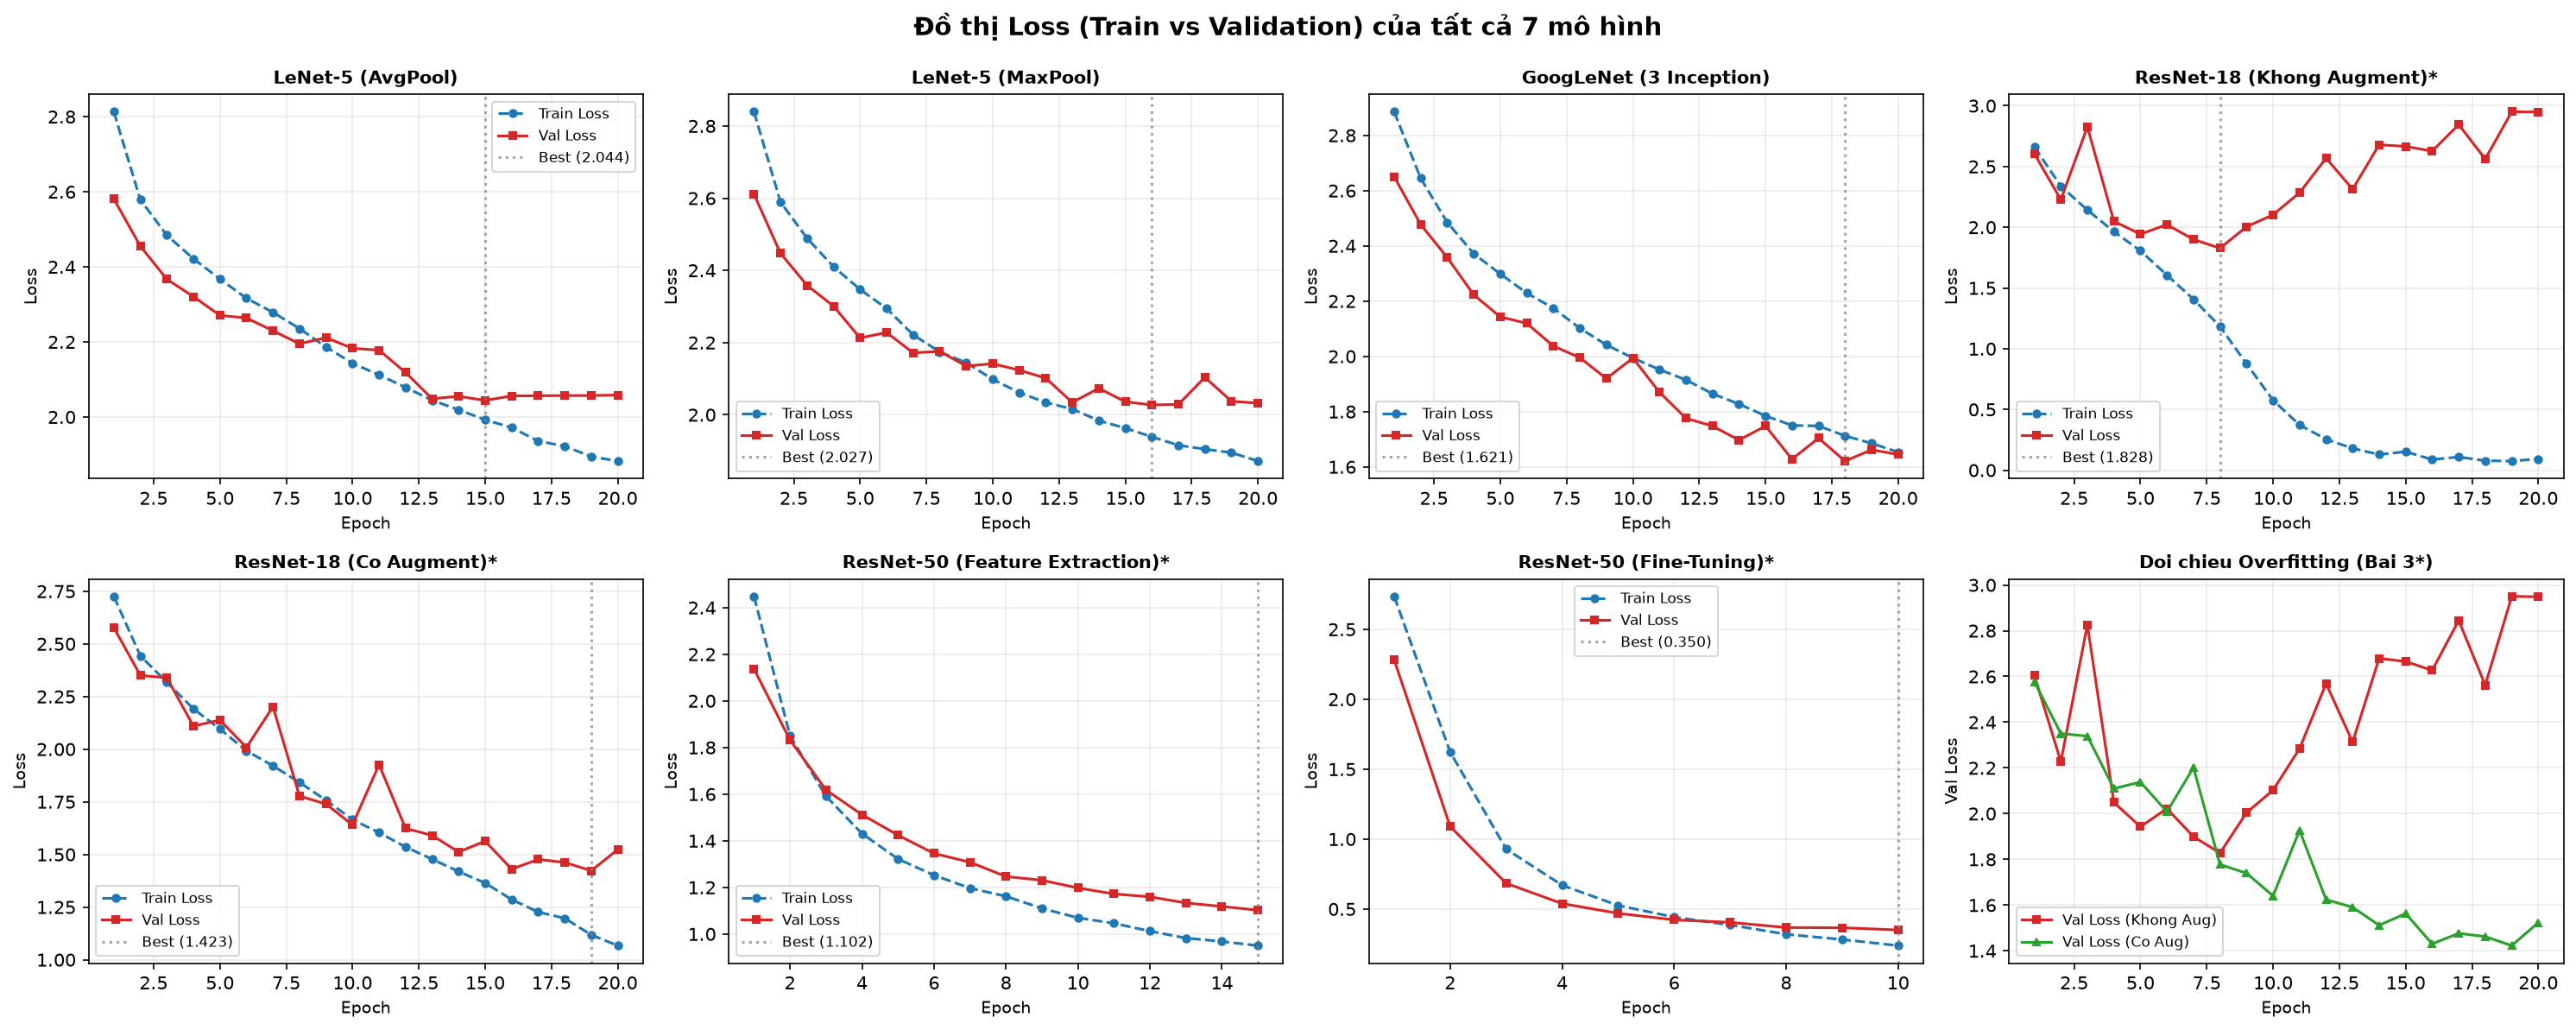


2. Đối chiếu hiện tượng Overfitting trên ResNet-18 (Không Augment vs Có Augment):


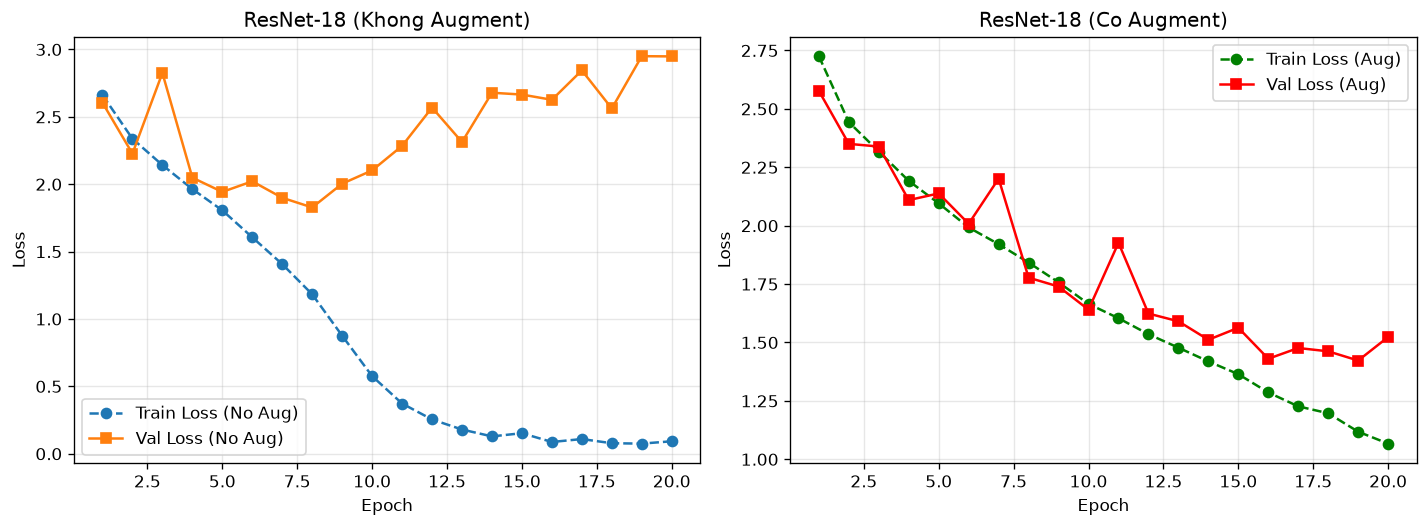

In [2]:
# 2. Vẽ và hiển thị đồ thị loss của tất cả 7 mô hình và đối chiếu overfitting
from IPython.display import Image, display
from pathlib import Path
from run_all import plot_all_loss_curves, plot_resnet18_comparison

# Tự động vẽ hoặc đọc từ file outputs đã lưu
plot_all_loss_curves()
plot_resnet18_comparison()

loss_path = Path("outputs/loss_all_models.png")
if loss_path.is_file():
    print("1. Đồ thị loss (train vs validation) của các mô hình qua các epoch:")
    display(Image(str(loss_path)))

cmp_path = Path("outputs/resnet18_overfitting_comparison.png")
if cmp_path.is_file():
    print("\n2. Đối chiếu hiện tượng overfitting trên ResNet-18 (không augment vs có augment):")
    display(Image(str(cmp_path)))


### Nhận xét đồ thị loss
**LeNet-5 và GoogLeNet**: train loss và validation loss cùng giảm và bám sát nhau, không bị phân kỳ nhưng chạm đáy ở mức loss cao (validation loss khoảng 1.6 - 2.0) do underfitting.   

**ResNet-18 (hiện tượng overfitting và vai trò của data augmentation)**
- **Đường loss và overfitting**: ở bản không augment, hai đường loss bắt đầu tách nhau từ epoch 4 (validation loss chạm đáy 1.83 rồi tăng vọt lên 3.34 ở epoch 20 trong khi train loss tiếp tục giảm). Nguyên nhân là mô hình có 11.2 triệu tham số (gấp 33 lần LeNet) nhưng tập dữ liệu nhỏ (~14 nghìn ảnh), dẫn đến việc mô hình học vẹt tập train.
- **Chênh lệch khi có data augmentation**: bản có augment giúp giữ validation loss ổn định quanh mức 1.42, macro-F1 tăng từ 0.4089 lên 0.4599 (chênh lệch +0.0510 hay +5.1%), accuracy tăng từ 41.26% lên 47.82%. Data augmentation tạo ra dữ liệu biến đổi qua từng epoch, đóng vai trò điều chuẩn giúp hạn chế overfitting.

**Pretrained ResNet-50 (transfer learning: feature extraction vs fine-tuning)**
- **So sánh feature extraction và fine-tuning**:
  + Feature extraction chỉ cập nhật 43,029 tham số của lớp classifier (backbone đóng băng, learning rate $10^{-3}$), đạt accuracy 61.36% và macro-F1 0.6153 sau 15 epoch.
  + Fine-tuning cập nhật toàn bộ 23,551,061 tham số với learning rate nhỏ $10^{-4}$, đạt accuracy 84.11% (test đạt 85.59%) và macro-F1 0.8389 (test đạt 0.8554) sau 10 epoch.
- **ResNet-50 (transfer learning)**: bản feature extraction hội tụ đều đặn (validation loss khoảng 1.10); bản fine-tuning hội tụ nhanh nhất, validation loss giảm dốc xuống 0.35 ở epoch 10 nhờ có sẵn trọng số tốt từ ImageNet.
- **So sánh transfer learning với huấn luyện từ đầu ở Bài 3**: transfer learning ở Bài 4 cho kết quả vượt trội so với huấn luyện từ đầu ở Bài 3 (macro-F1 0.8389 so với 0.4599, accuracy 84.11% so với 47.82%). Lý do là ResNet-50 đã được học trước trên hơn 1 triệu ảnh của ImageNet, có sẵn các bộ lọc đặc trưng thị giác tốt; quá trình fine-tuning chỉ cần tinh chỉnh lại cho dữ liệu món ăn, không bị thiếu dữ liệu như khi huấn luyện từ đầu.


## 3. Ma trận nhầm lẫn (confusion matrix)


Ma trận nhầm lẫn của tất cả 7 mô hình thực nghiệm:


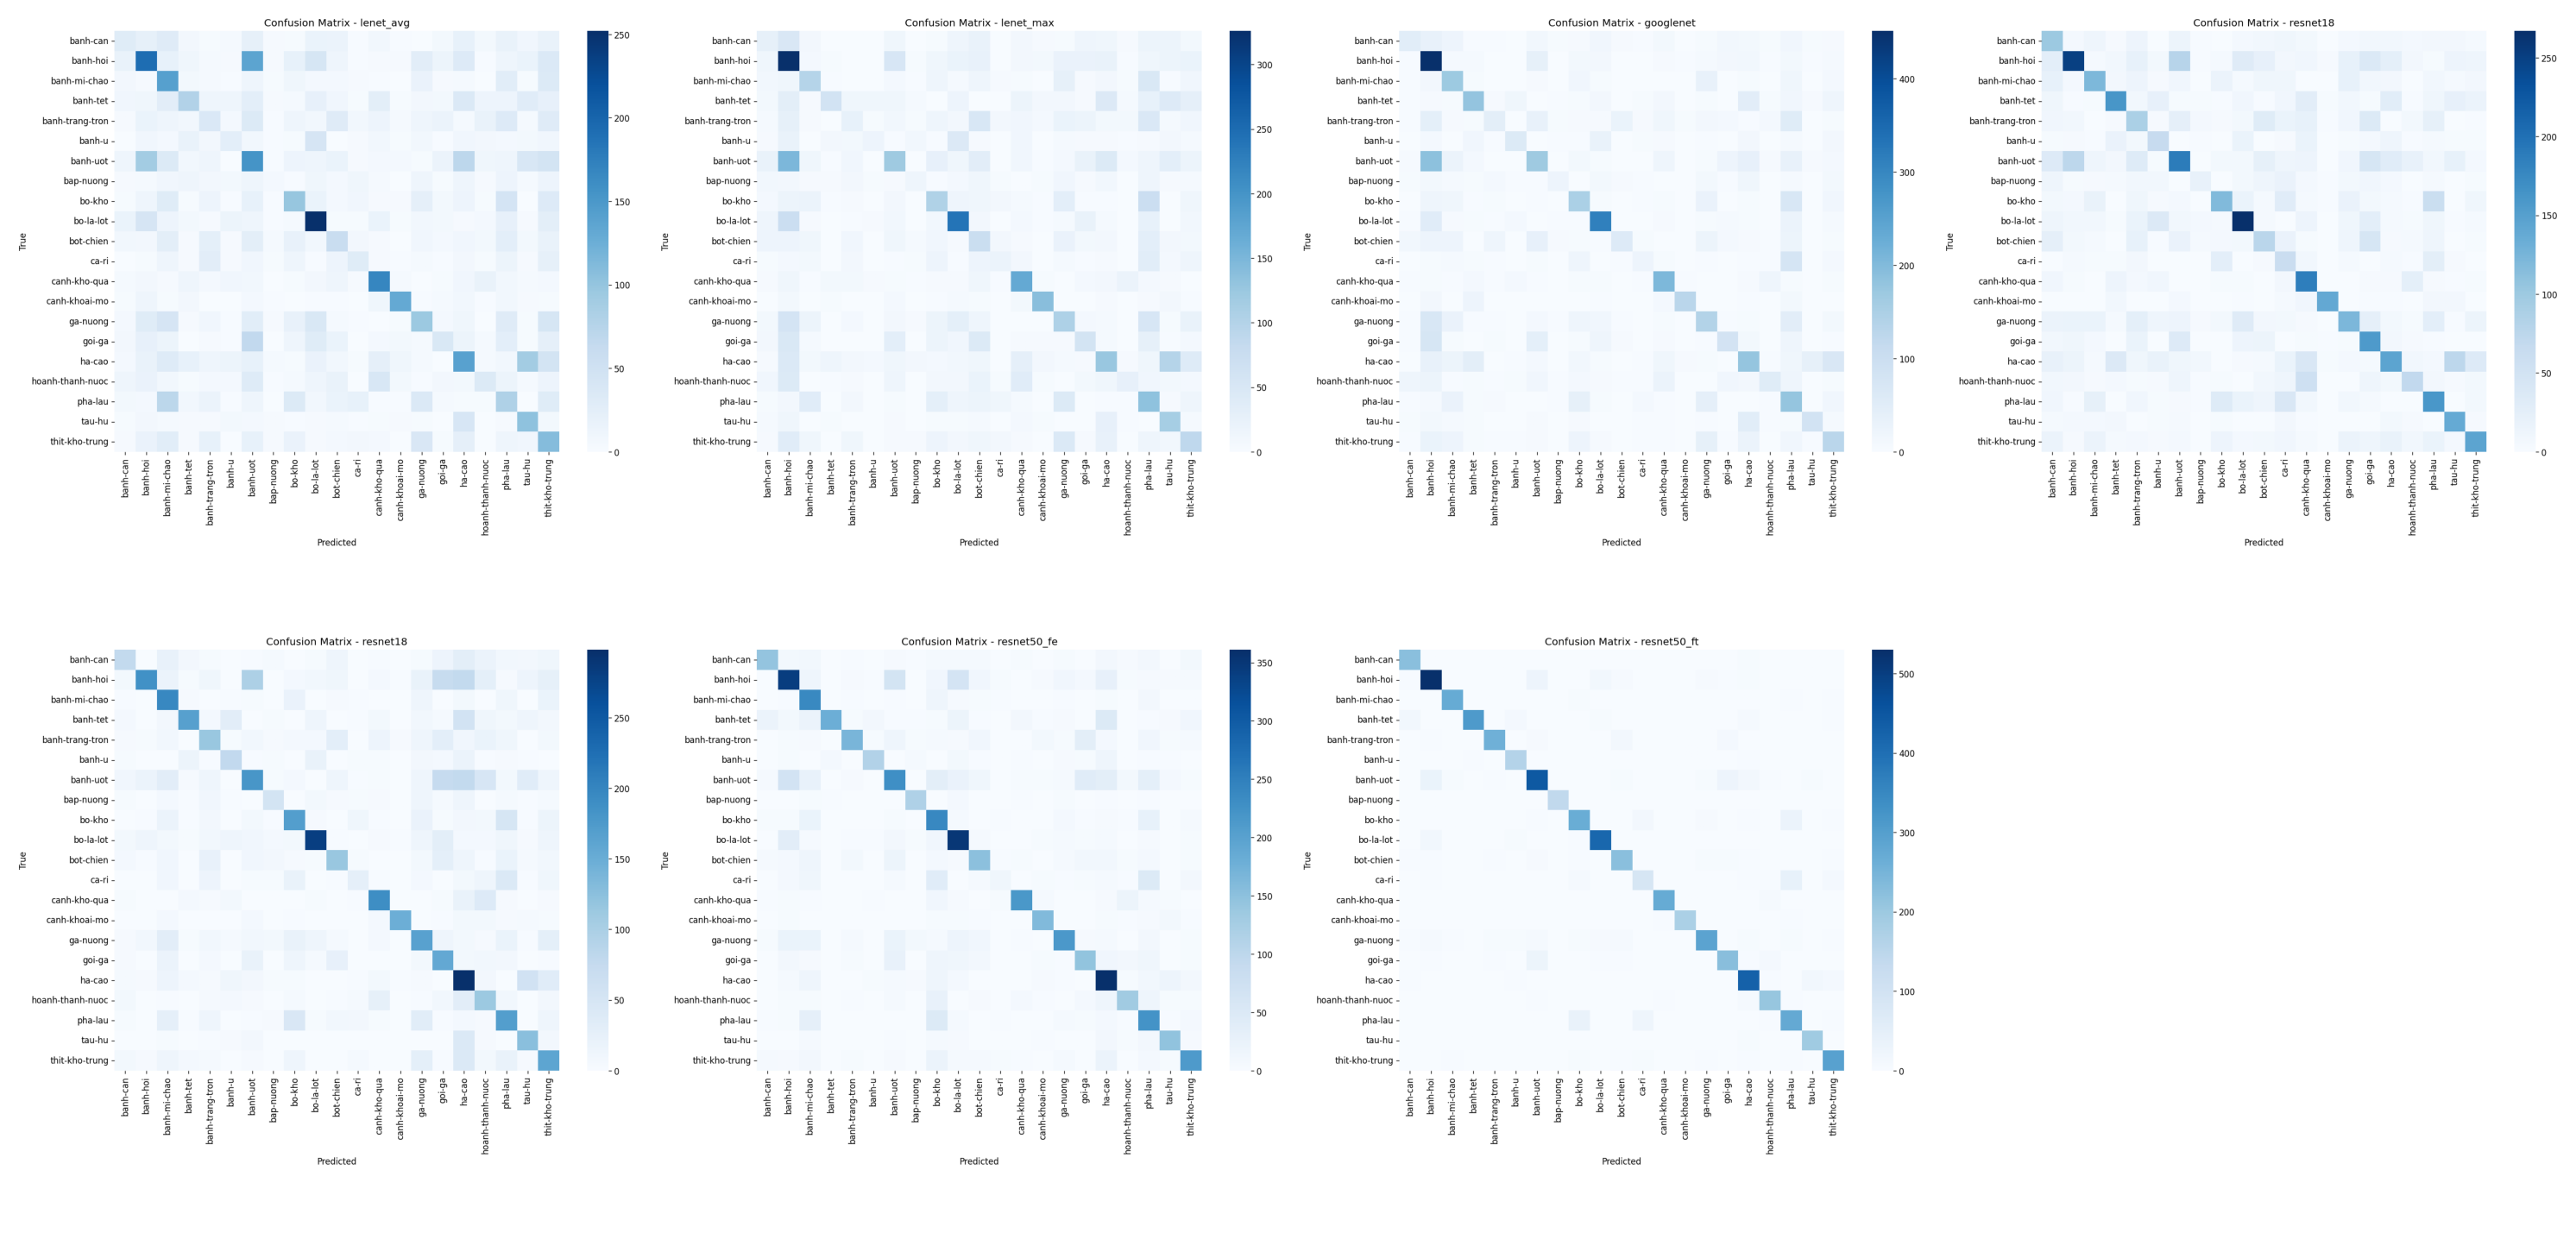

In [3]:
# 3. Hiển thị ma trận nhầm lẫn cho tất cả các mô hình
from IPython.display import Image, display
from pathlib import Path
from run_all import plot_all_confusion_matrices

# Cập nhật biểu đồ nếu cần
plot_all_confusion_matrices()

cm_all_path = Path("outputs/confusion_matrices_all.png")
if cm_all_path.is_file():
    print("Ma trận nhầm lẫn của tất cả 7 mô hình thực nghiệm:")
    display(Image(str(cm_all_path)))


### Nhận xét ma trận nhầm lẫn
- Đường chéo chính thể hiện số lượng dự đoán đúng, rõ nét nhất ở ResNet-50 fine-tuning (các lớp tập trung vào đường chéo chính với độ chính xác cao).
- Các lớp dễ bị nhầm lẫn với nhau là các món nước có nước dùng và sợi bún tương tự nhau như *bún bò Huế, bún riêu, bánh canh, hủ tiếu, phở*; hoặc các món có màu sắc và hình dạng tương đồng như *bánh xèo vs bánh khọt*.
